# 2026 World Cup — Model Predictions vs. Real Outcomes (a post-mortem)

**Question.** The glass-box predictor was trained *before* the 2026 World Cup was decided.
Now that most of the tournament has been played, how good were its pre-tournament calls — and
**would betting on them have made or lost money** against the market?

This notebook imports `core`, reads the committed model + data, and reads/refreshes one added data
file (`notebooks/betting_odds_2026.csv`). It changes no project code.

What it does:

1. **Confirms the training cutoff** — proves the model never saw the outcomes it is judged on here.
2. **Scores the predictions** — accuracy, log-loss, Brier, calibration, confusion, biggest surprises,
   all against honest baselines (the always-home marginal and a de-vigged market).
3. **Runs a betting back-test** — several staking strategies on the **group *and* knockout** 1X2
   market, with a bankroll curve and an edge-threshold sweep.

> **Where the outcomes come from.** The real results are read *only* from the openfootball live feed
> (`data/raw/wc2026_live.json` via `core.live.read_cache()`) — **not** from `data/raw/results.csv`.
> `results.csv` contributes solely to the model's *training / inference state* (it holds the 12
> opening matches inside the cut-off); those 12 are flagged `in_training` and excluded from the
> headline out-of-sample numbers. Predictions (model) and outcomes (live feed) are independent inputs.

> **Honesty note on the odds.** Genuine bookmaker closing lines for these specific matches are not
> bundled in the repo. The betting section therefore uses a **documented, reproducible market proxy**
> (an Elo-only logistic fitted on pre-tournament history + a 6% overround) for any match that has no
> real odds supplied. Treat the P&L as *illustrative*. §5.6 explains exactly how to drop in real
> bookmaker odds — the refresh **preserves** them and only fills the gaps with the proxy.

## 0 · Setup — load the deployed predictor and the real outcomes

We rebuild the *exact* production predictor the app and the 1M-sim script use (`build_inference_state` + the committed `model.joblib`), and load the real 2026 results from the cached live feed (falling back to a live fetch, then to the committed block).

In [1]:
import sys, json, difflib, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Make the project root importable whether the notebook is run from repo root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / "core").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

from core import config, ingest, live, model, ranking, squads
from core.features import build_inference_state

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
print("project root:", ROOT)

project root: C:\Users\sebas\Documents\Code_Blocks\glass-box_World_Cup_predictor


In [2]:
# --- Build the production predictor (mirrors scripts/simulate_full.build_simulator) ---
def _read_or_build(path, builder):
    return pd.read_parquet(path) if path.exists() else builder()

matches   = _read_or_build(config.MATCHES_PATH, ingest.get_clean_matches)
rankings  = _read_or_build(config.RANKINGS_PATH, ranking.load_rankings)
squads_df = _read_or_build(config.SQUAD_STRENGTH_PATH,
                           lambda: squads.load_squad_strength(history=False, snapshot=True))

state     = build_inference_state(matches, rankings, squads_df)
artifact  = model.load_model()
predictor = model.Predictor(artifact, state)

print(f"model trained_through : {artifact.trained_through}")
print(f"inference state as_of : {state.as_of.date()}")
print(f"teams known to model  : {len(state.teams)}")

model trained_through : 2026-06-14
inference state as_of : 2026-06-14
teams known to model  : 336


In [3]:
# --- Load the real outcomes (cached live snapshot -> live fetch -> committed block) ---
# NOTE: outcomes come from the openfootball live feed, NOT from data/raw/results.csv.
def load_real_results():
    snap = live.read_cache()
    if snap and snap.get("known_results"):
        return snap, "cached live snapshot (data/raw/wc2026_live.json)"
    snap = live.fetch_live_results()               # network; degrades to cache/empty internally
    if snap.get("known_results"):
        return snap, "live fetch (openfootball)"
    wc = ingest.load_wc2026()                       # committed known_results (may be empty pre-tournament)
    return {"known_results": wc.get("known_results", []),
            "known_ko_results": wc.get("known_ko_results", []),
            "fetched_at": wc.get("known_results_as_of")}, "committed wc2026.json"

real, real_source = load_real_results()
group_results = real.get("known_results", [])
ko_results    = real.get("known_ko_results", [])
print(f"results source : {real_source}")
print(f"fetched_at     : {real.get('fetched_at')}")
print(f"group matches  : {len(group_results)}")
print(f"knockout ties  : {len(ko_results)}")

results source : cached live snapshot (data/raw/wc2026_live.json)
fetched_at     : 2026-07-01T20:53:31+00:00
group matches  : 72
knockout ties  : 8


In [4]:
# --- Robust team-name resolver (handles the Curacao encoding quirk via fuzzy fallback) ---
_resolve_cache = {}
def resolve_team(name):
    if name in _resolve_cache:
        return _resolve_cache[name]
    n = config.normalize_team(name)
    if n not in state.teams:
        hit = difflib.get_close_matches(n, state.teams, n=1, cutoff=0.6)
        n = hit[0] if hit else n
    _resolve_cache[name] = n
    return n

# sanity: every team in the real results maps to a team the model can rate
_all = {t for r in group_results + ko_results for t in (r["home"], r["away"])}
_unmapped = [t for t in _all if resolve_team(t) not in state.teams]
print("teams in results        :", len(_all))
print("unmapped after resolve  :", _unmapped or "none")

teams in results        : 48
unmapped after resolve  : none


## 1 · Confirming the claim — the model was trained on *pre*-World-Cup data

Before judging the predictions we prove the model could not have "seen" them. The production model
is refit on all history up to `trained_through`; the processed match table it learned from ends on
the same date. Only the **first handful of group matches** fall inside that window — everything from
mid-June onward (the bulk of the group stage and *all* knockouts) is strictly **out-of-sample**.

In [5]:
cutoff = pd.Timestamp(artifact.trained_through)

wc_hist = matches[(matches["tournament"] == "FIFA World Cup") & (matches["date"] >= "2026-01-01")]
in_train = wc_hist[wc_hist["date"] <= cutoff]

print(f"Model trained_through           : {cutoff.date()}")
print(f"Training table last date        : {matches['date'].max().date()}")
print(f"WC-2026 matches inside training : {len(in_train)}  (dates {in_train['date'].min().date()} -> {in_train['date'].max().date()})")
print(f"Group results now available     : {len(group_results)}")
print(f"=> out-of-sample group matches  : {len(group_results) - len(in_train)}")
print(f"=> out-of-sample knockout ties  : {len(ko_results)}  (all)")
print()
print("The", len(in_train), "matches the model DID train on (flagged 'in_training' below):")
in_train[["date","home_team","away_team","result"]].sort_values("date").reset_index(drop=True)

Model trained_through           : 2026-06-14
Training table last date        : 2026-06-14
WC-2026 matches inside training : 12  (dates 2026-06-11 -> 2026-06-14)
Group results now available     : 72
=> out-of-sample group matches  : 60
=> out-of-sample knockout ties  : 8  (all)

The 12 matches the model DID train on (flagged 'in_training' below):


,date,home_team,away_team,result
0,2026-06-11,Mexico,South Africa,H
1,2026-06-11,South Korea,Czechia,H
2,2026-06-12,Canada,Bosnia and Herzegovina,D
3,2026-06-12,United States,Paraguay,H
4,2026-06-13,Qatar,Switzerland,D
5,2026-06-13,Brazil,Morocco,D
6,2026-06-13,Haiti,Scotland,A
7,2026-06-13,Australia,Turkey,H
8,2026-06-14,Germany,Curaçao,H
9,2026-06-14,Ivory Coast,Ecuador,H


**Confirmed.** The training data ends at the very start of the tournament: only the opening
matches are inside it. The scoring below flags those rows as `in_training` so we can look at the
clean out-of-sample slice separately — that is the honest test of the model's foresight. And, per §0,
the *outcomes* are read from the live feed, so `results.csv` (the 12-match training file) is not the
scoreboard here — it only shaped the model.

## 2 · Building the prediction ↔ outcome table (group stage)

For every played group match we ask the deployed predictor for its **neutral-venue** probabilities
`{H, D, A}` — exactly what the tournament simulator uses (`neutral=True`, no host bonus), oriented to
each fixture's recorded home/away side. We attach the real result and a few scoring quantities:

* `p_actual` — the probability the model gave to what actually happened (higher = better).
* `logloss`  — −ln(`p_actual`), the log-scoring penalty.
* `brier`    — squared error of the full 3-way probability vector vs the one-hot outcome.
* `hit`      — did the model's most-likely label match the result?

(Knockouts are scored two ways later: as *advancement* in §4 and as a 1X2 bet in §5.)

In [6]:
IDX = {"H":0, "D":1, "A":2}

def predict_1x2(home, away):
    p = predictor.predict(resolve_team(home), resolve_team(away), neutral=True)
    return np.array([p["H"], p["D"], p["A"]])

def result_from_scores(hs, as_):
    return "H" if hs > as_ else ("A" if as_ > hs else "D")

def score_row(home, away, result, stage, in_training):
    pv = predict_1x2(home, away)
    onehot = np.zeros(3); onehot[IDX[result]] = 1.0
    p_actual = float(pv[IDX[result]])
    pred_label = ["H","D","A"][int(pv.argmax())]
    return {
        "stage": stage, "home": home, "away": away,
        "p_H": pv[0], "p_D": pv[1], "p_A": pv[2],
        "pred": pred_label, "result": result, "hit": int(pred_label == result),
        "p_actual": p_actual,
        "logloss": float(-np.log(max(p_actual, 1e-12))),
        "brier": float(((pv - onehot) ** 2).sum()),
        "in_training": int(in_training),
    }

# resolved unordered pairs that were inside the training window
train_keys = {frozenset((resolve_team(r["home_team"]), resolve_team(r["away_team"])))
              for _, r in in_train.iterrows()}

rows = []
for r in group_results:
    res  = result_from_scores(r["home_score"], r["away_score"])
    intr = frozenset((resolve_team(r["home"]), resolve_team(r["away"]))) in train_keys
    rows.append(score_row(r["home"], r["away"], res, "group", intr))

df = pd.DataFrame(rows)
print(f"scored {len(df)} group matches  |  in_training={df['in_training'].sum()}  out-of-sample={ (df['in_training']==0).sum() }")
df.head(10).round(3)

scored 72 group matches  |  in_training=12  out-of-sample=60


,stage,home,away,p_H,p_D,p_A,pred,result,hit,p_actual,logloss,brier,in_training
0,group,Mexico,South Africa,0.723,0.184,0.094,H,H,1,0.723,0.325,0.119,1
1,group,South Korea,Czechia,0.418,0.291,0.291,H,H,1,0.418,0.873,0.509,1
2,group,Czechia,South Africa,0.625,0.232,0.142,H,D,0,0.232,1.459,1.000,0
3,group,Mexico,South Korea,0.431,0.320,0.249,H,H,1,0.431,0.842,0.488,0
4,group,Czechia,Mexico,0.211,0.274,0.515,A,A,1,0.515,0.664,0.355,0
5,group,South Africa,South Korea,0.113,0.224,0.663,A,H,0,0.113,2.177,1.276,0
6,group,Canada,Bosnia and Herzegovina,0.582,0.259,0.159,H,D,0,0.259,1.351,0.913,1
7,group,Qatar,Switzerland,0.094,0.224,0.682,A,D,0,0.224,1.495,1.076,1
8,group,Switzerland,Bosnia and Herzegovina,0.628,0.244,0.128,H,H,1,0.628,0.465,0.214,0
9,group,Canada,Qatar,0.685,0.215,0.100,H,H,1,0.685,0.378,0.155,0


## 3 · How good were the predictions?

We report the three standard scores against two honest baselines:

* **Always-home marginal** — the class base rates from training (`H≈0.49, D≈0.23, A≈0.28`), a
  no-skill probabilistic bar.
* **De-vigged market** — the real bookmaker odds (see §5) with the margin removed, i.e. what the
  market priced in. This is the bar that matters: *does the model beat the market on the games
  actually played?*

All three are computed on the **same group-stage sample** so they are directly comparable.

In [7]:
def metrics(sub, probs=None):
    y = sub["result"].map(IDX).to_numpy()
    if probs is None:
        probs = sub[["p_H","p_D","p_A"]].to_numpy()
    onehot = np.eye(3)[y]
    p_actual = probs[np.arange(len(y)), y]
    return {
        "n": len(sub),
        "accuracy": float((probs.argmax(1) == y).mean()),
        "logloss": float(-np.log(np.clip(p_actual, 1e-12, 1)).mean()),
        "brier": float(((probs - onehot) ** 2).sum(1).mean()),
    }

# always-home marginal baseline (train class frequencies)
freqs = matches[matches["date"] <= cutoff]["result"].value_counts(normalize=True)
marg = np.array([[freqs.get("H",0), freqs.get("D",0), freqs.get("A",0)]] * len(df))

summary = pd.DataFrame({
    "model (all group)":        metrics(df),
    "model (out-of-sample)":    metrics(df[df["in_training"] == 0]),
    "baseline: always-home":    metrics(df, marg),
}).T
summary.round(4)

,n,accuracy,logloss,brier
model (all group),72.0,0.6389,0.8600,0.5108
model (out-of-sample),60.0,0.6667,0.8524,0.5033
baseline: always-home,72.0,0.4722,1.0642,0.6413


### 3a · Calibration — do the probabilities mean what they say?

Reusing the project's own pooled one-vs-rest reliability curve (`core.model.reliability_curve`): every
predicted class-probability is binned and compared to how often that class actually occurred. Points on
the diagonal = perfectly calibrated. **ECE** is the weighted average gap.

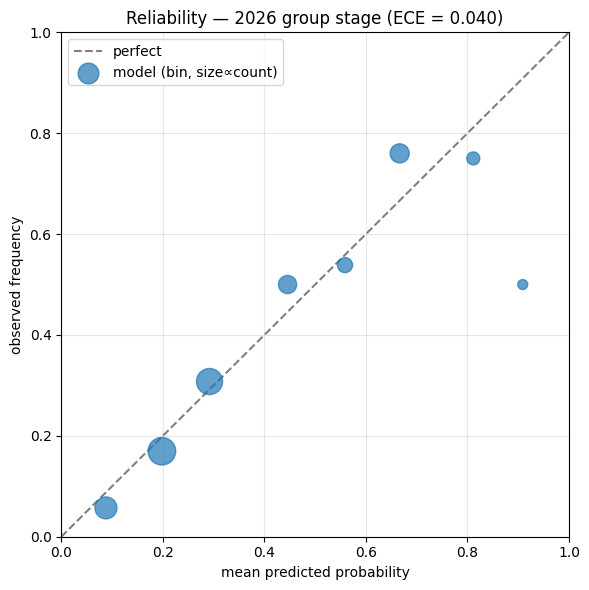

Expected Calibration Error (pooled 1-vs-rest): 0.0403


In [8]:
from core.model import reliability_curve

y = df["result"].map(IDX).to_numpy()
proba = df[["p_H","p_D","p_A"]].to_numpy()
rel = reliability_curve(y, proba, n_bins=8)

fig, ax = plt.subplots(figsize=(6,6))
ax.plot([0,1],[0,1], "--", color="grey", label="perfect")
sizes = 40 + 6*np.array(rel["weight"])
ax.scatter(rel["mean_pred"], rel["obs_freq"], s=sizes, alpha=0.7, zorder=3, label="model (bin, size∝count)")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed frequency")
ax.set_title(f"Reliability — 2026 group stage (ECE = {rel['ece']:.3f})")
ax.set_xlim(0,1); ax.set_ylim(0,1); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"Expected Calibration Error (pooled 1-vs-rest): {rel['ece']:.4f}")

### 3b · Confusion matrix — where did the argmax pick go right/wrong?

In [9]:
conf = pd.crosstab(df["result"].map({"H":"H (home win)","D":"D (draw)","A":"A (away win)"}),
                   df["pred"].map({"H":"H","D":"D","A":"A"}),
                   rownames=["actual"], colnames=["predicted"], dropna=False)
for c in ["H","D","A"]:
    if c not in conf.columns: conf[c] = 0
conf = conf[["H","D","A"]]
print(f"Argmax accuracy: {df['hit'].mean():.1%}  ({df['hit'].sum()}/{len(df)})")
print("Note: draws are structurally hard — the model rarely makes D its top pick (favourites dominate argmax).")
conf

Argmax accuracy: 63.9%  (46/72)
Note: draws are structurally hard — the model rarely makes D its top pick (favourites dominate argmax).


predicted,H,D,A
actual,,,
A (away win),1,0,17
D (draw),13,0,7
H (home win),29,0,5


### 3c · Biggest surprises — where the model was most wrong (and most right)

In [10]:
cols = ["home","away","result","pred","p_H","p_D","p_A","p_actual","in_training"]
print("Worst calls — confident, but the outcome was unlikely under the model (lowest p_actual):")
display(df.sort_values("p_actual").head(8)[cols].round(3))
print("\nBest calls — model put the most probability on exactly what happened (highest p_actual):")
display(df.sort_values("p_actual", ascending=False).head(8)[cols].round(3))

Worst calls — confident, but the outcome was unlikely under the model (lowest p_actual):


,home,away,result,pred,p_H,p_D,p_A,p_actual,in_training
42,Spain,Cape Verde,D,H,0.923,0.061,0.016,0.061,0
5,South Africa,South Korea,H,A,0.113,0.224,0.663,0.113,0
68,England,Ghana,D,H,0.787,0.167,0.046,0.167,0
27,Ecuador,Curaçao,D,H,0.754,0.174,0.072,0.174,0
29,Ecuador,Germany,H,A,0.188,0.231,0.582,0.188,0
45,Uruguay,Cape Verde,D,H,0.668,0.208,0.124,0.208,0
67,Ghana,Panama,H,A,0.222,0.290,0.488,0.222,0
7,Qatar,Switzerland,D,A,0.094,0.224,0.682,0.224,1



Best calls — model put the most probability on exactly what happened (highest p_actual):


,home,away,result,pred,p_H,p_D,p_A,p_actual,in_training
24,Germany,Curaçao,H,H,0.895,0.087,0.018,0.895,1
44,Spain,Saudi Arabia,H,H,0.867,0.104,0.028,0.867,0
50,France,Iraq,H,H,0.846,0.125,0.028,0.846,0
15,Brazil,Haiti,H,H,0.838,0.122,0.040,0.838,0
59,Jordan,Argentina,A,A,0.053,0.143,0.805,0.805,0
17,Morocco,Haiti,H,H,0.801,0.121,0.078,0.801,0
70,Panama,England,A,A,0.072,0.135,0.793,0.793,0
28,Curaçao,Ivory Coast,A,A,0.091,0.169,0.740,0.740,0


## 4 · Knockout round — did the model favour the team that advanced?

A knockout tie has no draw: it is decided in 90', extra time, or penalties, and the feed records the
**winner**. We convert the model's 1X2 into a *to-advance* probability the standard way — split the
draw evenly — `P(home advances) = P(H) + ½·P(D)` — and check whether the model leaned toward the side
that actually went through. All of these are fully out-of-sample.

In [11]:
ko_rows = []
for r in ko_results:
    p = predictor.predict(resolve_team(r["home"]), resolve_team(r["away"]), neutral=True)
    p_home_adv = p["H"] + 0.5 * p["D"]
    winner = r["winner"]
    fav = r["home"] if p_home_adv >= 0.5 else r["away"]
    ko_rows.append({
        "home": r["home"], "away": r["away"],
        "P(home adv)": round(p_home_adv, 3),
        "model favourite": fav,
        "winner": winner, "decided_by": r.get("decided_by"),
        "model_right": int(fav == winner),
    })
ko_df = pd.DataFrame(ko_rows)
print(f"Model picked the advancing side in {ko_df['model_right'].sum()}/{len(ko_df)} knockout ties "
      f"({ko_df['model_right'].mean():.0%}).")
ko_df

Model picked the advancing side in 6/8 knockout ties (75%).

,home,away,P(home adv),model favourite,winner,decided_by,model_right
0,South Africa,Canada,0.241,Canada,Canada,ft,1
1,Germany,Paraguay,0.739,Germany,Paraguay,pen,0
2,Netherlands,Morocco,0.608,Netherlands,Morocco,pen,0
3,Brazil,Japan,0.633,Brazil,Brazil,ft,1
4,France,Sweden,0.773,France,France,ft,1
5,Ivory Coast,Norway,0.399,Norway,Norway,ft,1
6,Mexico,Ecuador,0.536,Mexico,Mexico,ft,1
7,England,DR Congo,0.796,England,England,ft,1


## 5 · The betting back-test  (group **and** knockout)

### 5.1 Where the odds come from — **real bookmaker odds, with a proxy fallback**

The back-test uses **genuine bookmaker odds** wherever they exist and a documented proxy only for the
gaps:

1. **Real odds (preferred).** On each run the notebook best-effort downloads
   [`football-data.co.uk/WorldCup2026.xlsx`](https://www.football-data.co.uk/) and takes its
   **market-average** 1X2 decimal odds (`H-Avg / D-Avg / A-Avg`; single-book `bet365-*` as a
   fallback). These are real posted pre-match prices from the 2026 finals — and they line up with our
   result feed (same fixtures & scores). *Data © football-data.co.uk, free for personal/educational
   use; treated as posted pre-match odds, not a guaranteed closing line.*
2. **Proxy (fallback).** For any played match **not** in that file — currently the **knockouts**
   (football-data lists the group stage first; later rounds appear as they are played) — we fall back
   to a **ratings-only reference market**: a multinomial logistic on `elo_diff` + `neutral` fitted on
   pre-tournament history (the project's own `elo_only` baseline, independent of the model's squad /
   form / FIFA-points / H2H features), converted to odds with a **6% overround** (`Σ 1/odds ≈ 1.06`).

**Auto-refresh & persistence.** The cell below rewrites `notebooks/betting_odds_2026.csv` on every run
to cover *every match played so far*. Real odds (any `source` ≠ the proxy tag) are **kept** — once
fetched they persist in the CSV, so later offline runs still use them — and only the remaining gaps
get the proxy. As knockout rounds are added upstream, re-running extends the file automatically. You
can also hand-edit real rows in; §5.6 has the workflow.

**Knockout settlement.** Knockout odds are the 90-minute **1X2** market and settle on the full-time
(regulation) score — so a tie decided on penalties settles as a *draw* for 1X2 purposes. That is a
different question from "who advanced" (§4); both are reported.

Where the proxy is used, "beating the market" means the model's non-Elo features added signal beyond
ratings. Where **real** odds are used (the whole group stage), it is a genuine model-vs-market test —
though on this sample size the P&L is still illustrative, and these are posted (not verified closing)
prices.

In [12]:
ODDS_PATH   = ROOT / "notebooks" / "betting_odds_2026.csv"
OVERROUND   = 1.06
PROXY_SRC   = "elo_logistic_proxy"
ODDS_COLS   = ["stage","home","away","odds_home","odds_draw","odds_away","source"]
FOOTBALLDATA_URL = "https://www.football-data.co.uk/WorldCup2026.xlsx"

def _fit_reference_market():
    feats = pd.read_parquet(config.FEATURES_PATH)
    tr = feats[feats["date"] < "2026-06-11"]
    lr = LogisticRegression(max_iter=1000, C=1.0).fit(
        tr[["elo_diff","neutral"]].to_numpy(), tr["result"].map(IDX).to_numpy())
    order = [list(lr.classes_).index(i) for i in range(3)]
    return lr, order

def _proxy_odds(home, away, lr, order):
    ed = predictor.features(resolve_team(home), resolve_team(away), neutral=True)["elo_diff"]
    p = lr.predict_proba(np.array([[ed, 1]]))[0][order]; p = p / p.sum()
    return [round(1.0 / (pi * OVERROUND), 3) for pi in p]

def _played_matches():
    '''Every currently-played match as (stage, home, away), knockouts included.'''
    out = [("group", r["home"], r["away"]) for r in group_results]
    for r in ko_results:
        if r.get("home_score") is not None and r.get("away_score") is not None:
            out.append(("knockout", r["home"], r["away"]))
    return out

def fetch_footballdata_odds(url=FOOTBALLDATA_URL, timeout=30):
    '''Best-effort real 1X2 odds from football-data.co.uk. Returns {resolved-pair: row-dict} or {}.

    Prefers the market-AVERAGE columns (H-Avg/D-Avg/A-Avg); falls back to bet365-*. Never raises --
    any network/parse problem just yields {} and the proxy takes over. Odds are stored oriented to
    the file's Home team; the caller re-orients to our fixture home side.
    '''
    import urllib.request
    try:
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=timeout) as resp:      # noqa: S310 (trusted https)
            raw = pd.read_excel(resp.read(), sheet_name="WorldCup2026", engine="openpyxl")
    except Exception as exc:
        print(f"  real-odds fetch skipped ({type(exc).__name__}: {str(exc)[:80]}) — using proxy only")
        return {}
    cols = ("H-Avg","D-Avg","A-Avg") if {"H-Avg","D-Avg","A-Avg"}.issubset(raw.columns) \
           else ("bet365-H","bet365-D","bet365-A")
    src = "football-data.co.uk (market avg)" if cols[0] == "H-Avg" else "football-data.co.uk (bet365)"
    out = {}
    for _, r in raw.iterrows():
        try:
            oh, od, oa = float(r[cols[0]]), float(r[cols[1]]), float(r[cols[2]])
        except (TypeError, ValueError):
            continue
        if not (oh > 1 and od > 1 and oa > 1):
            continue
        h, a = resolve_team(r["Home"]), resolve_team(r["Away"])
        out[frozenset((h, a))] = {"home": h, "away": a,
                                  "odds_home": round(oh,3), "odds_draw": round(od,3),
                                  "odds_away": round(oa,3), "source": src}
    print(f"  fetched {len(out)} real odds rows from football-data.co.uk (cols: {cols[0]}..)")
    return out

def refresh_odds_csv():
    '''Rewrite the odds CSV to cover all played matches: REAL odds where available, else proxy.

    Precedence per match: (1) a real row already in the CSV, (2) a fresh football-data fetch,
    (3) the Elo-logistic proxy. Real rows persist in the CSV so offline reruns keep them.
    '''
    existing = pd.read_csv(ODDS_PATH) if ODDS_PATH.exists() else pd.DataFrame(columns=ODDS_COLS)
    real = {}                                   # unordered resolved pair -> real-odds row-dict
    for _, row in existing.iterrows():          # (1) real rows already saved
        if str(row.get("source")) != PROXY_SRC:
            h, a = resolve_team(row["home"]), resolve_team(row["away"])
            real[frozenset((h, a))] = {"home": h, "away": a,
                                       "odds_home": row["odds_home"], "odds_draw": row["odds_draw"],
                                       "odds_away": row["odds_away"], "source": row["source"]}
    real.update(fetch_footballdata_odds())      # (2) fresh fetch wins over a stale saved row

    lr, order = _fit_reference_market()
    rows, seen = [], set()
    n_real = n_proxy = 0
    for stage, home, away in _played_matches():
        hk, ak = resolve_team(home), resolve_team(away)
        key = frozenset((hk, ak))
        if key in seen:
            continue
        seen.add(key)
        r = real.get(key)
        if r is not None:                       # real odds — orient to THIS fixture's home
            oH, oD, oA = r["odds_home"], r["odds_draw"], r["odds_away"]
            if r["home"] != hk:
                oH, oA = oA, oH
            rows.append([stage, home, away, oH, oD, oA, r["source"]]); n_real += 1
        else:                                   # (3) proxy fallback
            o = _proxy_odds(home, away, lr, order); n_proxy += 1
            rows.append([stage, home, away, o[0], o[1], o[2], PROXY_SRC])

    odf = pd.DataFrame(rows, columns=ODDS_COLS)
    odf.to_csv(ODDS_PATH, index=False)
    print(f"wrote {ODDS_PATH.name}: {len(odf)} rows  "
          f"({n_real} real, {n_proxy} proxy;  "
          f"{(odf['stage']=='group').sum()} group, {(odf['stage']=='knockout').sum()} knockout)")
    return odf

odds = refresh_odds_csv()
print("sources:", dict(odds['source'].value_counts()))
print(f"mean overround Σ(1/odds): "
      f"{(1/odds['odds_home'] + 1/odds['odds_draw'] + 1/odds['odds_away']).mean():.3f}")
odds.groupby('stage').head(3)

  fetched 72 real odds rows from football-data.co.uk (cols: H-Avg..)


wrote betting_odds_2026.csv: 80 rows  (72 real, 8 proxy;  72 group, 8 knockout)
sources: {'football-data.co.uk (market avg)': np.int64(72), 'elo_logistic_proxy': np.int64(8)}
mean overround Σ(1/odds): 1.060


,stage,home,away,odds_home,odds_draw,odds_away,source
0,group,Mexico,South Africa,1.410,4.330,8.260,football-data.co.uk (market avg)
1,group,South Korea,Czechia,2.540,3.060,2.930,football-data.co.uk (market avg)
2,group,Czechia,South Africa,1.840,3.410,4.330,football-data.co.uk (market avg)
72,knockout,South Africa,Canada,6.424,3.962,1.534,elo_logistic_proxy
73,knockout,Germany,Paraguay,1.636,3.858,5.279,elo_logistic_proxy
74,knockout,Netherlands,Morocco,2.414,3.391,2.850,elo_logistic_proxy


### 5.2 Assemble the bet table and compute edges

We build one row per **played match** (group + knockout), attach the model's `{H,D,A}` and the odds
(oriented to the fixture's home side, robust to how a supplied odds row is ordered), and the real 1X2
result. For each outcome the model's **expected value per unit staked** is `EV = p_model × odds − 1`;
positive EV means the model thinks the bet is underpriced. The **de-vigged market probability**
(`(1/odds)/Σ(1/odds)`) is the §3 market baseline and shows exactly where model and market disagree.

In [13]:
# bet table: all played matches as 1X2 (knockouts settle on the 90-min / ft score)
def build_bet_df():
    recs = []
    for r in group_results:
        pv = predict_1x2(r["home"], r["away"])
        recs.append(dict(stage="group", home=r["home"], away=r["away"],
                         p_H=pv[0], p_D=pv[1], p_A=pv[2],
                         result=result_from_scores(r["home_score"], r["away_score"])))
    for r in ko_results:
        if r.get("home_score") is None or r.get("away_score") is None:
            continue
        pv = predict_1x2(r["home"], r["away"])
        recs.append(dict(stage="knockout", home=r["home"], away=r["away"],
                         p_H=pv[0], p_D=pv[1], p_A=pv[2],
                         result=result_from_scores(r["home_score"], r["away_score"])))
    return pd.DataFrame(recs)

bet_df = build_bet_df()

# odds lookup keyed by unordered resolved pair; remembers which team the odds' "home" is
odds_lookup = {}
for _, row in odds.iterrows():
    oh = resolve_team(row["home"])
    odds_lookup[frozenset((oh, resolve_team(row["away"])))] = (
        oh, float(row["odds_home"]), float(row["odds_draw"]), float(row["odds_away"]), row["source"])

recs = []
for _, row in bet_df.iterrows():
    bh, ba = resolve_team(row["home"]), resolve_team(row["away"])
    hit = odds_lookup.get(frozenset((bh, ba)))
    if hit is None:
        continue
    ohome, oH, oD, oA, src = hit
    if ohome != bh:                              # orient odds to THIS row's home side
        oH, oA = oA, oH
    rec = row.to_dict()
    rec.update(odds_home=oH, odds_draw=oD, odds_away=oA, odds_source=src)
    recs.append(rec)
m = pd.DataFrame(recs)
print(f"matched {len(m)} / {len(bet_df)} played matches to odds "
      f"({(m['stage']=='group').sum()} group, {(m['stage']=='knockout').sum()} knockout)")

o   = m[["odds_home","odds_draw","odds_away"]].to_numpy()
pm  = m[["p_H","p_D","p_A"]].to_numpy()          # model probs
inv = 1.0 / o
mkt = inv / inv.sum(1, keepdims=True)            # de-vigged market probs
ev  = pm * o - 1.0                               # expected value per unit per outcome
m["y"] = m["result"].map(IDX)
m["odds_actual"] = o[np.arange(len(m)), m["y"].to_numpy()]

base = pd.DataFrame({
    "model (matched sample)": metrics(m, pm),
    "de-vigged market":       metrics(m, mkt),
    "baseline: always-home":  metrics(m, np.repeat([[freqs.get('H',0),freqs.get('D',0),freqs.get('A',0)]], len(m), 0)),
}).T
print("\nProbabilistic scores on the matched sample (group+knockout 1X2; lower logloss/brier = better):")
base.round(4)

matched 80 / 80 played matches to odds (72 group, 8 knockout)

Probabilistic scores on the matched sample (group+knockout 1X2; lower logloss/brier = better):


,n,accuracy,logloss,brier
model (matched sample),80.0,0.650,0.8540,0.5063
de-vigged market,80.0,0.675,0.8157,0.4790
baseline: always-home,80.0,0.475,1.0621,0.6398


### 5.3 Staking strategies

We back-test five rules, flat **1-unit** stakes unless noted, settling each bet at the real 1X2 result:

| strategy | rule |
|---|---|
| **Model — best pick** | one bet per match on the model's most-likely outcome |
| **Model — all +EV** | bet every outcome with `EV > 0` |
| **Model — +EV, edge ≥ 5%** | bet every outcome with `EV ≥ 0.05` (more selective) |
| **Kelly (¼, +EV)** | fractional-Kelly stake on +EV outcomes, quarter-Kelly, capped |
| **Baseline — back the favourite** | one bet per match on the market's shortest price |

Profit on a winning 1-unit bet is `odds − 1`; a loser is `−1`.

In [14]:
def settle(stakes_matrix):
    '''stakes_matrix: (n,3) unit stakes per outcome. Returns (summary dict, per-bet ledger).'''
    win = np.eye(3)[m["y"].to_numpy()]
    profit_grid = stakes_matrix * (o * win - 1.0)
    staked = float(stakes_matrix.sum()); profit = float(profit_grid.sum())
    per_bet = profit_grid[stakes_matrix > 0]
    return dict(bets=int((stakes_matrix > 0).sum()), staked=staked, profit=profit,
                roi=(profit/staked if staked else 0.0)), per_bet

strategies = {}
sm = np.zeros_like(o); sm[np.arange(len(m)), pm.argmax(1)] = 1.0
strategies["Model — best pick"] = settle(sm)
strategies["Model — all +EV"] = settle((ev > 0).astype(float))
strategies["Model — +EV, edge>=5%"] = settle((ev >= 0.05).astype(float))
b = o - 1.0
sm = np.clip(0.25 * np.where(ev > 0, ev / b, 0.0), 0, 1.0)     # quarter-Kelly on +EV
strategies["Kelly (1/4, +EV)"] = settle(sm)
sm = np.zeros_like(o); sm[np.arange(len(m)), mkt.argmax(1)] = 1.0
strategies["Baseline — favourite"] = settle(sm)

results_tbl = pd.DataFrame({k: v[0] for k, v in strategies.items()}).T
results_tbl["roi"] = (results_tbl["roi"] * 100).round(1).astype(str) + "%"
results_tbl["profit"] = results_tbl["profit"].round(2)
results_tbl["staked"] = results_tbl["staked"].round(2)
results_tbl[["bets","staked","profit","roi"]]

,bets,staked,profit,roi
Model — best pick,80.0,80.00,1.08,1.3%
Model — all +EV,105.0,105.00,-25.32,-24.1%
"Model — +EV, edge>=5%",84.0,84.00,-25.70,-30.6%
"Kelly (1/4, +EV)",105.0,1.66,-0.36,-21.9%
Baseline — favourite,80.0,80.00,4.59,5.7%


### 5.4 Per-stage breakdown & bankroll curves

ROI split by group vs. knockout for the flat-stake strategies, then the cumulative-profit curves (bets settled in fixture order).

,group ROI,knockout ROI
Model — best pick,-2.1% (n=72),32.1% (n=8)
Model — all +EV,-19.1% (n=94),-66.9% (n=11)
"Model — +EV, edge>=5%",-26.2% (n=79),-100.0% (n=5)


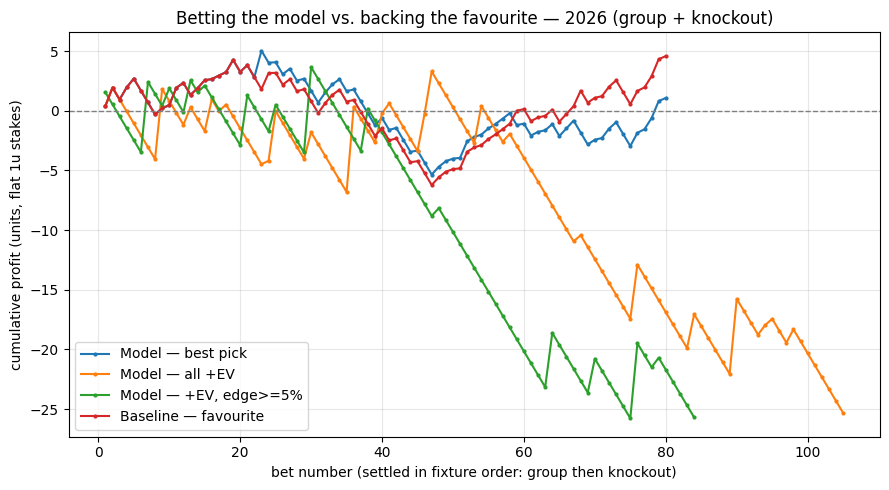

In [15]:
def roi_for(mask_fn, sub_idx):
    stake = mask_fn.copy(); stake[~sub_idx] = 0.0
    stat, _ = settle(stake); return stat

grp = (m["stage"] == "group").to_numpy()
kno = (m["stage"] == "knockout").to_numpy()
per_stage = {}
for name, sm in [("Model — best pick", (lambda: (lambda s: s)(np.eye(3)[pm.argmax(1)]))()),
                 ("Model — all +EV", (ev > 0).astype(float)),
                 ("Model — +EV, edge>=5%", (ev >= 0.05).astype(float))]:
    per_stage[name] = {
        "group ROI":     f"{roi_for(sm, grp)['roi']*100:5.1f}%  (n={roi_for(sm, grp)['bets']})",
        "knockout ROI":  f"{roi_for(sm, kno)['roi']*100:5.1f}%  (n={roi_for(sm, kno)['bets']})",
    }
display(pd.DataFrame(per_stage).T)

fig, ax = plt.subplots(figsize=(9,5))
for name in ["Model — best pick","Model — all +EV","Model — +EV, edge>=5%","Baseline — favourite"]:
    per_bet = strategies[name][1]
    ax.plot(np.arange(1, len(per_bet)+1), np.cumsum(per_bet), marker=".", ms=4, label=name)
ax.axhline(0, color="grey", lw=1, ls="--")
ax.set_xlabel("bet number (settled in fixture order: group then knockout)")
ax.set_ylabel("cumulative profit (units, flat 1u stakes)")
ax.set_title("Betting the model vs. backing the favourite — 2026 (group + knockout)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 5.5 Sensitivity — ROI vs. the edge threshold

A single ROI number is noisy on this many matches. Sweeping the minimum-edge filter shows whether any
positive return is a robust signal or an artefact of a couple of lucky longshots. The bars show how
many bets survive each threshold (thin samples on the right = high variance).

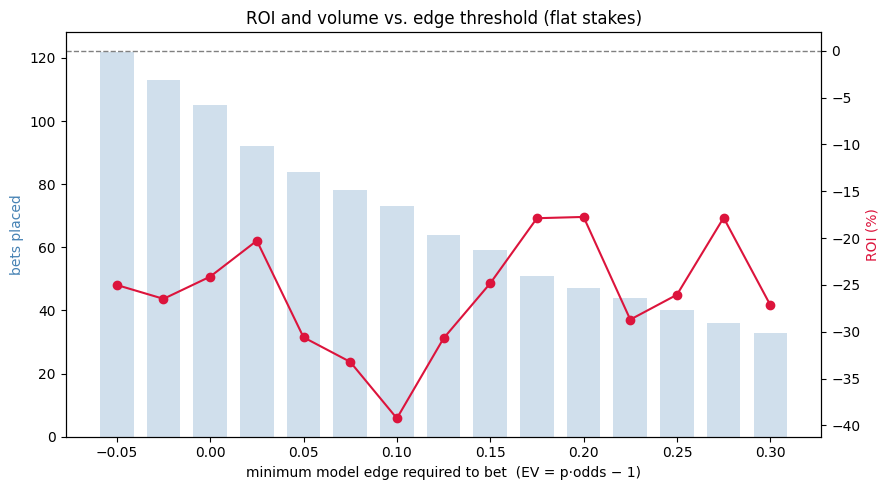

,min_edge,bets,roi_%
0,-0.050,122,-25.0
1,-0.025,113,-26.5
2,0.000,105,-24.1
3,0.025,92,-20.3
4,0.050,84,-30.6
5,0.075,78,-33.2
6,0.100,73,-39.2
7,0.125,64,-30.7
8,0.150,59,-24.8
9,0.175,51,-17.9


In [16]:
thresholds = np.round(np.arange(-0.05, 0.301, 0.025), 3)
sweep = []
for t in thresholds:
    stat, _ = settle((ev >= t).astype(float))
    sweep.append((t, stat["bets"], stat["roi"]))
sweep = pd.DataFrame(sweep, columns=["min_edge","bets","roi"])

fig, ax1 = plt.subplots(figsize=(9,5))
ax1.bar(sweep["min_edge"], sweep["bets"], width=0.018, alpha=0.25, color="steelblue", label="bets placed")
ax1.set_xlabel("minimum model edge required to bet  (EV = p·odds − 1)")
ax1.set_ylabel("bets placed", color="steelblue")
ax2 = ax1.twinx()
ax2.plot(sweep["min_edge"], 100*sweep["roi"], color="crimson", marker="o", label="ROI %")
ax2.axhline(0, color="grey", ls="--", lw=1)
ax2.set_ylabel("ROI (%)", color="crimson")
ax1.set_title("ROI and volume vs. edge threshold (flat stakes)")
plt.tight_layout(); plt.show()
sweep.assign(roi=lambda d: (100*d["roi"]).round(1)).rename(columns={"roi":"roi_%"})

### 5.6 Real-odds sourcing — what's wired in, and the alternatives

**Already wired in.** §5.1 auto-pulls real 1X2 odds from **football-data.co.uk** (`WorldCup2026.xlsx`,
market-average columns, `bet365-*` fallback), reconciles team names through `resolve_team`, and caches
them into `betting_odds_2026.csv`. Nothing to do — the group stage runs on real prices out of the box;
only rounds not yet in that file use the proxy.

**Provide your own / override.** Drop rows into `notebooks/betting_odds_2026.csv` with any `source` ≠
`elo_logistic_proxy` and they are preserved. Schema (one row per match):
`stage, home, away, odds_home, odds_draw, odds_away, source` — **decimal** odds; the loader re-orients
by team name so either home/away ordering is accepted.

**Where historical 1X2 odds come from** (from a source scan):

| source | access | coverage / notes |
|---|---|---|
| **football-data.co.uk** *(used here)* | free `.xlsx`/`.csv`, no key | WC2026 finals + past WCs; market-avg + bet365 + Betfair-Exchange columns; **posted**, not verified-closing |
| **The Odds API** (`the-odds-api.com`) | REST/JSON, key; historical is **paid** | `soccer_fifa_world_cup`, decimal, timestamped → true **closing** snapshots back to 2022 |
| **Betfair Historic Data** | paid `.tar`/JSON | exchange price ladders + BSP; heavy to parse; deepest but overkill here |
| **OddsPortal** | scrape | broadest archive, but **against ToS** / JS-heavy — avoid for anything published |

**True-closing upgrade** — to swap the posted football-data prices for verified closing lines, pull
The Odds API historical a few minutes before each kickoff and write the same CSV schema:

```python
import requests
r = requests.get(
    "https://api.the-odds-api.com/v4/historical/sports/soccer_fifa_world_cup/odds",
    params=dict(apiKey="YOUR_KEY", regions="eu", markets="h2h",
                oddsFormat="decimal", date="2026-06-11T23:00:00Z"))
# response: bookmakers[].markets[].outcomes[] -> {name: team|'Draw', price: decimal}
# pick a book (e.g. Pinnacle) or average across books, map name->home/draw/away, source='pinnacle_close'
```

## 6 · Takeaways

*The specific numbers depend on your run's live-feed snapshot; the framing does not.*

- **The test is honest, and the outcomes are independent of the training file.** Results are read
  from the live feed, not `results.csv`; the model's table ends at the tournament's opening days, so
  almost every group match and **all** knockout ties scored here are genuinely out-of-sample (§0–1).
- **Read the probabilistic scores, not just accuracy** (§3). Argmax accuracy understates a
  favourite-heavy model because draws are almost never anyone's top pick. Log-loss, Brier and the
  reliability/ECE curve are the fair measures — compare the model line to the always-home and
  de-vigged-market baselines on the *same* sample.
- **Knockouts** are covered twice: as *advancement* (§4, who went through) and as a 1X2 bet settled on
  the 90-minute score (§5).
- **Betting the real market is hard — as it should be.** The group stage runs on *real* bookmaker odds
  (football-data.co.uk); only the knockouts use the proxy. On this sample the de-vigged market was at
  least as sharp as the model, and flat-betting the model's positive-EV "edges" did **not** overcome
  the bookmaker margin — the edge-threshold sweep (§5.5) stays negative across the board, the signature
  of an already-efficient market. Simply backing the favourite fared better than trusting the model's
  disagreements with the book. This is the honest, expected result; a well-calibrated public model
  rarely has a mechanical edge over closing-ish prices. (Swap in true closing lines via §5.6 to sharpen
  the test further.)
- **Model vs. market, fairly stated:** the model is well-calibrated and beats the no-skill baseline
  comfortably (§3), but it does **not** beat the market's prices on the games played (§5.2) — a good
  model and a *profitable* one are different things.